In [1]:
import ast
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from scipy.stats import bootstrap

In [2]:
df = pd.read_csv("../generated_data/serial_position_effect_results_cleaned.csv")
df

,Gender,Enthusiasm,Assertiveness,Compassion,Politeness,Industriousness,Orderliness,Volatility,Withdrawal,Intellect,...,experiment_group,serial_position_effect_map_20,serial_position_effect_map_40,serial_position_effect_map_80,Serial_Position_Effect_20,Serial_Position_Effect_40,Serial_Position_Effect_80,llm,persona,thinking
0,male,2.31,3.65,3.33,3.39,3.76,4.75,3.14,2.97,3.92,...,2,"{""ladder"": 1, ""lantern"": 2, ""bridge"": 3, ""penc...","{""forest"": 1, ""jungle"": 2, ""garage"": 3, ""butte...","{""suitcase"": 1, ""pillow"": 2, ""quilt"": 3, ""cook...","ladder, lantern, bridge, pencil, factory, whis...","forest, jungle, garage, butterfly, glove, quil...","butterfly, dolphin, jacket, teapot, volcano, r...",deepseek-v4-pro,description,enabled
1,male,2.86,2.94,3.28,3.29,2.91,3.74,3.28,3.17,3.70,...,1,"{""violin"": 1, ""jacket"": 2, ""drum"": 3, ""rocket""...","{""fountain"": 1, ""helmet"": 2, ""bottle"": 3, ""jac...","{""bottle"": 1, ""turtle"": 2, ""meadow"": 3, ""clock...","violin, jacket, drum, rocket, horizon, blanket...","fountain, helmet, bottle, backpack, beach, win...","bottle, meadow, feather, library, forest, pill...",deepseek-v4-pro,description,enabled
2,male,3.78,2.45,4.12,2.89,2.06,3.49,2.64,3.08,3.62,...,1,"{""igloo"": 1, ""zebra"": 2, ""balloon"": 3, ""snowfl...","{""owl"": 1, ""rabbit"": 2, ""castle"": 3, ""flower"":...","{""pillow"": 1, ""garden"": 2, ""teapot"": 3, ""dolph...","igloo, zebra, balloon, snowflake, notebook, la...","owl, rabbit, castle, flower, apple, island, oc...","pillow, garden, teapot, dolphin, backpack, dia...",deepseek-v4-pro,description,enabled
3,male,2.86,2.64,4.16,3.49,2.53,2.99,2.44,3.11,3.09,...,2,"{""igloo"": 1, ""lighthouse"": 2, ""island"": 3, ""ca...","{""harvest"": 1, ""engine"": 2, ""beach"": 3, ""castl...","{""feather"": 1, ""drum"": 2, ""fountain"": 3, ""whis...","igloo, lighthouse, island, castle, turtle, vio...","beach, castle, drum, balloon, feather, violin,...","feather, rabbit, dolphin, owl, turtle, zebra, ...",deepseek-v4-pro,description,enabled
4,male,3.53,4.20,4.14,2.00,3.17,3.36,3.07,3.44,3.50,...,2,"{""bridge"": 1, ""beehive"": 2, ""chair"": 3, ""blank...","{""jacket"": 1, ""drum"": 2, ""mountain"": 3, ""ocean...","{""forest"": 1, ""ladder"": 2, ""lantern"": 3, ""kett...","bridge, beehive, chair, blanket, ocean, zebra,...","mountain, ocean, eagle, butterfly, jungle, cas...","forest, lantern, island, diamond, zebra, owl, ...",deepseek-v4-pro,description,enabled
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3595,female,3.69,2.86,3.54,3.16,2.69,2.52,2.90,2.54,3.88,...,1,"{""pencil"": 1, ""teapot"": 2, ""dolphin"": 3, ""bask...","{""airplane"": 1, ""quilt"": 2, ""lantern"": 3, ""eag...","{""clock"": 1, ""airplane"": 2, ""rope"": 3, ""key"": ...","pencil, teapot, dolphin, basket, guitar, light...","airplane, quilt, lantern, eagle, mirror, kettl...","clock, airplane, rope, key, candle, suitcase, ...",deepseek-v4-flash,no_persona,disabled
3596,female,3.31,2.18,3.66,3.07,2.82,2.84,2.93,2.63,2.46,...,2,"{""acorn"": 1, ""umbrella"": 2, ""yacht"": 3, ""dolph...","{""violin"": 1, ""river"": 2, ""island"": 3, ""whistl...","{""quilt"": 1, ""engine"": 2, ""owl"": 3, ""lantern"":...","acorn, umbrella, yacht, dolphin, magnet, islan...","violin, river, island, whistle, igloo, beach, ...","quilt, engine, owl, lantern, whistle, garden, ...",deepseek-v4-flash,no_persona,disabled
3597,female,2.38,4.42,3.16,2.43,2.20,1.27,2.29,2.41,3.92,...,2,"{""rainbow"": 1, ""drum"": 2, ""pillow"": 3, ""owl"": ...","{""engine"": 1, ""garage"": 2, ""key"": 3, ""rope"": 4...","{""guitar"": 1, ""yacht"": 2, ""quilt"": 3, ""jungle""...","rainbow, drum, pillow, owl, acorn, blanket, bu...","engine, garage, key, rope, nest, eagle, balloo...","guitar, yacht, quilt, jungle, balloon, flower,...",deepseek-v4-flash,no_persona,disabled
3598,female,3.89,3.72,2.98,1.65,2.31,2.63,3.02,4.26,2.21,...,1,"{""garage"": 1, ""library"": 2, ""drum"": 3, ""kettle...","{""rabbit"": 1, ""fo

In [3]:
def parse_serial_map(x):
    return ast.literal_eval(x)

def parse_response(x):
    # Split on commas and clean whitespace
    return [
        item.strip()
        for item in str(x).split(",")
        if item.strip()
    ]

def response_to_positions(row, n):
    serial_map = row[f"serial_map_{n}"]
    
    return [
        serial_map[item]
        for item in row[f"response_items_{n}"]
        if item in serial_map
    ]

for n in [20, 40, 80]:
    df[f"serial_map_{n}"] = df[f"serial_position_effect_map_{n}"].apply(parse_serial_map)
    df[f"response_items_{n}"] = df[f"Serial_Position_Effect_{n}"].apply(parse_response)
    df[f"response_positions_{n}"] = df.apply(lambda row: response_to_positions(row, n), axis=1)
df

,Gender,Enthusiasm,Assertiveness,Compassion,Politeness,Industriousness,Orderliness,Volatility,Withdrawal,Intellect,...,thinking,serial_map_20,response_items_20,response_positions_20,serial_map_40,response_items_40,response_positions_40,serial_map_80,response_items_80,response_positions_80
0,male,2.31,3.65,3.33,3.39,3.76,4.75,3.14,2.97,3.92,...,enabled,"{'ladder': 1, 'lantern': 2, 'bridge': 3, 'penc...","[ladder, lantern, bridge, pencil, factory, whi...","[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14...","{'forest': 1, 'jungle': 2, 'garage': 3, 'butte...","[forest, jungle, garage, butterfly, glove, qui...","[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14...","{'suitcase': 1, 'pillow': 2, 'quilt': 3, 'cook...","[butterfly, dolphin, jacket, teapot, volcano, ...","[46, 47, 48, 49, 50, 51, 52, 53, 54, 55, 56, 5..."
1,male,2.86,2.94,3.28,3.29,2.91,3.74,3.28,3.17,3.70,...,enabled,"{'violin': 1, 'jacket': 2, 'drum': 3, 'rocket'...","[violin, jacket, drum, rocket, horizon, blanke...","[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14...","{'fountain': 1, 'helmet': 2, 'bottle': 3, 'jac...","[fountain, helmet, bottle, backpack, beach, wi...","[1, 2, 3, 5, 7, 9, 12, 13, 14, 15, 16, 17, 18,...","{'bottle': 1, 'turtle': 2, 'meadow': 3, 'clock...","[bottle, meadow, feather, library, forest, pil...","[1, 3, 5, 7, 9, 11, 13, 15, 17, 19, 21, 23, 25..."
2,male,3.78,2.45,4.12,2.89,2.06,3.49,2.64,3.08,3.62,...,enabled,"{'igloo': 1, 'zebra': 2, 'balloon': 3, 'snowfl...","[igloo, zebra, balloon, snowflake, notebook, l...","[1, 2, 3, 4, 5, 6, 8, 9, 10, 12, 13, 14, 15, 1...","{'owl': 1, 'rabbit': 2, 'castle': 3, 'flower':...","[owl, rabbit, castle, flower, apple, island, o...","[1, 2, 3, 4, 5, 8, 12, 14, 17, 21, 31, 32, 34,...","{'pillow': 1, 'garden': 2, 'teapot': 3, 'dolph...","[pillow, garden, teapot, dolphin, backpack, di...","[1, 2, 3, 4, 5, 9, 10, 13, 14, 20, 26, 30, 37,..."
3,male,2.86,2.64,4.16,3.49,2.53,2.99,2.44,3.11,3.09,...,enabled,"{'igloo': 1, 'lighthouse': 2, 'island': 3, 'ca...","[igloo, lighthouse, island, castle, turtle, vi...","[1, 2, 3, 5, 8, 10, 15, 16, 20, 18]","{'harvest': 1, 'engine': 2, 'beach': 3, 'castl...","[beach, castle, drum, balloon, feather, violin...","[3, 4, 7, 8, 14, 17, 19, 22, 23, 28, 34, 39, 2...","{'feather': 1, 'drum': 2, 'fountain': 3, 'whis...","[feather, rabbit, dolphin, owl, turtle, zebra,...","[1, 5, 8, 10, 18, 28, 80, 36, 27, 30, 43, 35, ..."
4,male,3.53,4.20,4.14,2.00,3.17,3.36,3.07,3.44,3.50,...,enabled,"{'bridge': 1, 'beehive': 2, 'chair': 3, 'blank...","[bridge, beehive, chair, blanket, ocean, zebra...","[1, 2, 3, 4, 5, 7, 8, 9, 10, 11, 12, 13, 15, 1...","{'jacket': 1, 'drum': 2, 'mountain': 3, 'ocean...","[mountain, ocean, eagle, butterfly, jungle, ca...","[3, 4, 25, 33, 22, 34, 35, 36, 37, 39, 31, 21,...","{'forest': 1, 'ladder': 2, 'lantern': 3, 'kett...","[forest, lantern, island, diamond, zebra, owl,...","[1, 3, 6, 15, 11, 12, 20, 32, 40, 43, 72, 75, ..."
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3595,female,3.69,2.86,3.54,3.16,2.69,2.52,2.90,2.54,3.88,...,disabled,"{'pencil': 1, 'teapot': 2, 'dolphin': 3, 'bask...","[pencil, teapot, dolphin, basket, guitar, ligh...","[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14...","{'airplane': 1, 'quilt': 2, 'lantern': 3, 'eag...","[airplane, quilt, lantern, eagle, mirror, kett...","[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14...","{'clock': 1, 'airplane': 2, 'rope': 3, 'key': ...","[clock, airplane, rope, key, candle, suitcase,...","[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14..."
3596,female,3.31,2.18,3.66,3.07,2.82,2.84,2.93,2.63,2.46,...,disabled,"{'acorn': 1, 'umbrella': 2, 'yacht': 3, 'dolph...","[acorn, umbrella, yacht, dolphin, magnet, isla...","[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14...","{'violin': 1, 'river': 2, 'island': 3, 'whistl...","[violin, river, island, whistle, igloo, beach,...","[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14...","{'quilt': 1, 'engine': 2, 'owl': 3, 'lantern':...","[qu

In [4]:
for n in [20, 40, 80]:
    df[f"response_length_{n}"] = df[f"response_items_{n}"].str.len()

mean_response_length = (
    df
    .groupby(["llm", "persona", "thinking"])[
        ["response_length_20", "response_length_40", "response_length_80"]
    ]
    .mean()
    .reset_index()
    .round(2)
)

mean_response_length

,llm,persona,thinking,response_length_20,response_length_40,response_length_80
0,deepseek-v4-flash,description,disabled,19.85,39.16,78.29
1,deepseek-v4-flash,description,enabled,18.59,32.43,50.65
2,deepseek-v4-flash,no_persona,disabled,19.89,39.13,77.43
3,deepseek-v4-flash,no_persona,enabled,19.72,37.32,65.38
4,deepseek-v4-flash,raw_persona,disabled,19.87,39.38,81.52
5,deepseek-v4-flash,raw_persona,enabled,18.25,30.18,47.40
6,deepseek-v4-pro,description,disabled,19.68,39.14,76.92
7,deepseek-v4-pro,description,enabled,15.47,25.41,39.84
8,deepseek-v4-pro,no_persona,disabled,19.97,39.81,79.59
9,deepseek-v4-pro,no_persona,enabled,15.05,25.93,40.58


In [ ]:
# murd62.egg: https://raw.githubusercontent.com/ContextLab/quail/master/quail/data/murd62.egg
# Murdock (1962): https://doi.org/10.1037/h0045106
import math
import numpy as np, pandas as pd
from pickle import Unpickler

d = Unpickler(open("murd62.egg", "rb")).load()
rows = []

for subj, (pres, rec) in enumerate(zip(d["pres"], d["rec"])):
    for trial, (p, r) in enumerate(zip(pres, rec)):
        
        cond, n = p[0]["Condition"], p[0]["List length"]
        recalled = {x["Temporal"] + 1 for x in r
                    if isinstance(x, dict) and "Temporal" in x and not (isinstance(x.get("item"), float) and math.isnan(x["item"]))}
        for pos in range(1, n + 1):
            rows.append((cond, n, subj, trial, pos, pos in recalled))

t = pd.DataFrame(rows, columns=["condition", "list_length", "subject", "trial", "position", "recalled"])
subj = t.groupby(["condition", "list_length", "subject", "position"])["recalled"].mean().reset_index()

spc = (subj.groupby(["condition", "list_length", "position"])["recalled"]
          .agg(proportion="mean", sd="std", n_subjects="count").reset_index())

spc["se"] = spc["sd"] / np.sqrt(spc["n_subjects"])
spc["n_trials"] = t.groupby(["condition", "position"]).size().values
human_data = spc.drop(columns="sd").round(4)
#.to_csv(sys.argv[2], index=False)


In [ ]:
N_BOOT = 10_000
rng = np.random.default_rng(42)
conds = ["llm", "persona", "thinking"]
alpha = 0.05 / df.groupby(conds).ngroups       # 12 conditions -> 99.58% CIs
lower_ci, upper_ci = alpha / 2, 1 - alpha / 2

def recall_curves(n):
    """Proportion recalling each position, with a bootstrap CI over observations, per condition."""
    out = []
    for condition, data in df.groupby(conds):

        X = np.array([np.isin(np.arange(1, n + 1), positions) 
                      for positions in data[f"response_positions_{n}"]], dtype=float)

        res = bootstrap(
            (X,), 
            np.mean, 
            axis=0,                 
            confidence_level=1 - alpha,            
            n_resamples=N_BOOT, 
            method="percentile",
            random_state=rng
            )           
        lo, hi = res.confidence_interval.low, res.confidence_interval.high

        out.append(pd.DataFrame({
                    **dict(zip(conds, condition)), 
                    "position": np.arange(1, n + 1),
                    "proportion": X.mean(0), 
                    "lower_CI": lo, 
                    "upper_CI": hi,
                    "n": len(X)
                    }))
    return pd.concat(out, ignore_index=True)

spe_curves = {n: recall_curves(n) for n in [20, 40, 80]}


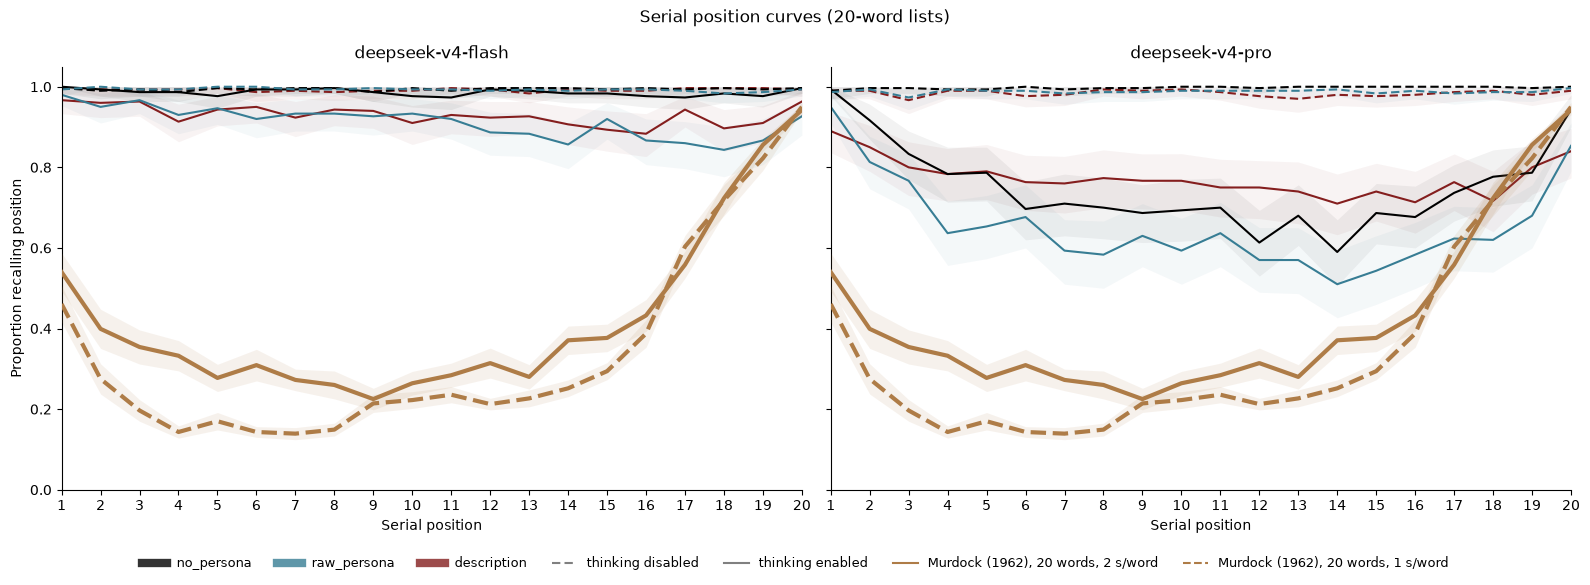

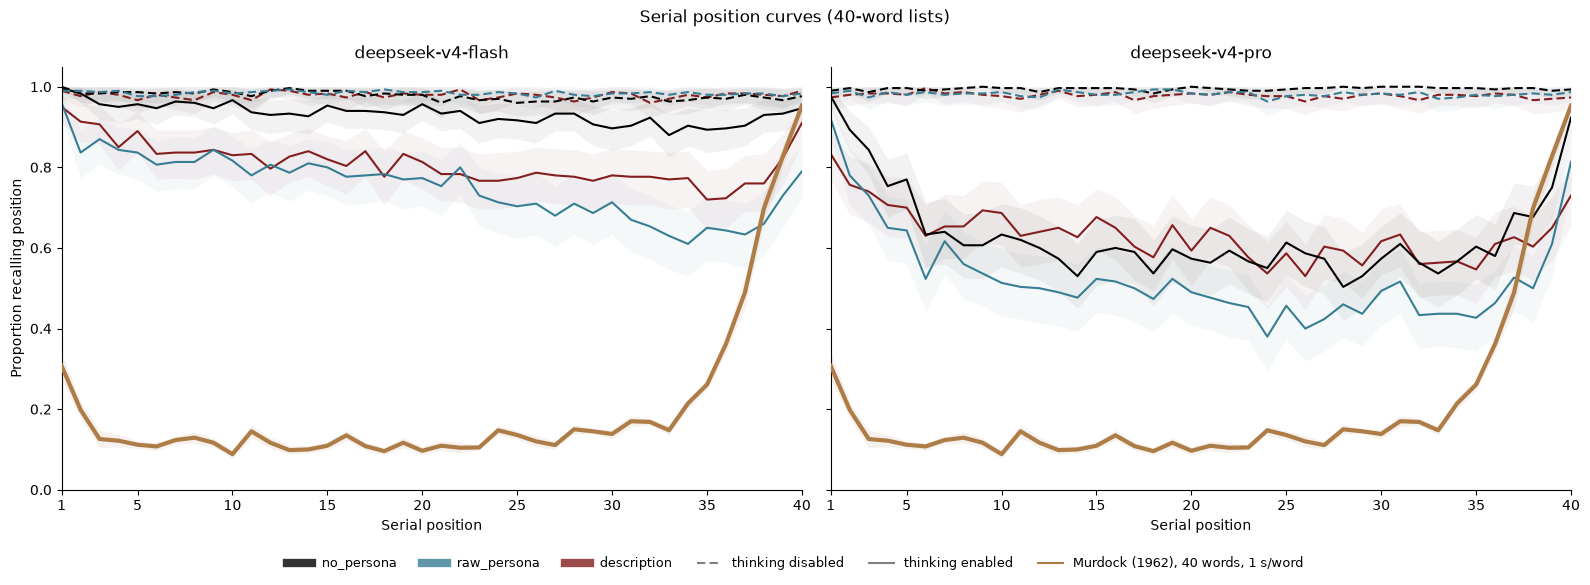

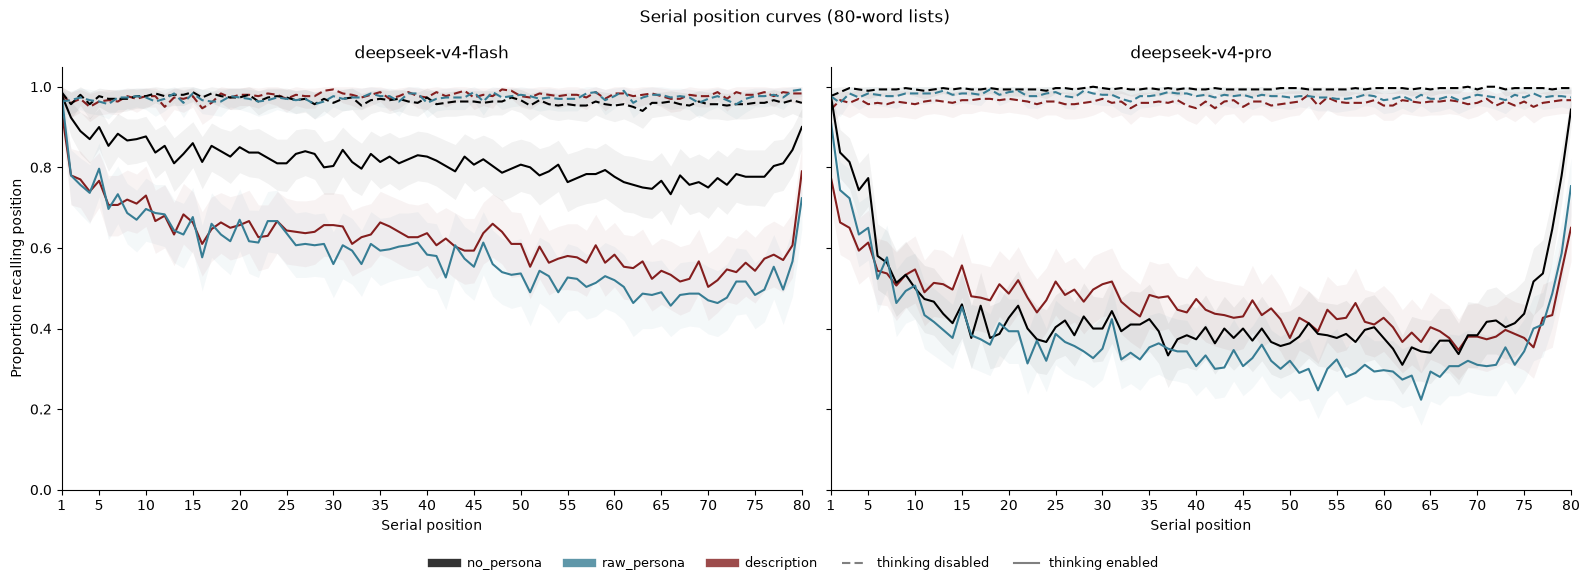

In [11]:
# list length -> Murdock conditions to overlay (label, line style)
HUMAN_CONDS = {
    20: [("LL20-2s", "Murdock (1962), 20 words, 2 s/word", "-"),
         ("LL20-1s", "Murdock (1962), 20 words, 1 s/word", "--")],
    40: [("LL40-1s", "Murdock (1962), 40 words, 1 s/word", "-")],
    80: [],
}
HUMAN_COLOR = "#ae7c47" 
PERSONAS = ["no_persona", "raw_persona", "description"]
COLORS = dict(zip(PERSONAS, ["#000000", "#377D94", "#841E1E"]))   
LLMS = ["deepseek-v4-flash", "deepseek-v4-pro"]

def plot_spe(n):
    curves = spe_curves[n]
    fig, axes = plt.subplots(1, 2, figsize=(16, 5.5), sharey=True)

    for ax, llm in zip(axes, LLMS):
        for (persona, thinking), c in curves[curves["llm"] == llm].groupby(["persona", "thinking"]):
            ax.fill_between(
                c["position"], 
                c["lower_CI"], 
                c["upper_CI"],
                color=COLORS[persona], 
                alpha=.05, 
                linewidth=0
                )     # 99.58% bootstrap CI
            ax.plot(
                c["position"],
                c["proportion"], 
                color=COLORS[persona],
                linestyle=(0, (4, 2)) if thinking == "disabled" else "-",
                marker=None, 
                linewidth=1.5
                )

        # Human reference (Murdock, 1962), ±1 SE across participants
        for cond, label, ls in HUMAN_CONDS[n]:
            h = human_data[human_data["condition"] == cond]
            ax.fill_between(
                h["position"], 
                h["proportion"] - h["se"], 
                h["proportion"] + h["se"],
                color=HUMAN_COLOR, 
                alpha=.1, 
                linewidth=0, 
                zorder=4
                )
            ax.plot(
                h["position"], 
                h["proportion"], 
                color=HUMAN_COLOR, 
                linestyle=ls, 
                linewidth=3,
                marker=None,
                zorder=5
                )

        ticks = [1] + list(range(5, n + 1, 5)) if n > 20 else range(1, n + 1)
        ax.set(title=llm, xlabel="Serial position", xticks=ticks, xlim=(1, n), ylim=(0, 1.05))
    axes[0].set_ylabel("Proportion recalling position")
    sns.despine()

    line = lambda **kw: plt.Line2D([], [], **kw)
    handles = [line(color=COLORS[p], linewidth=6, alpha=.8) for p in PERSONAS]
    labels = PERSONAS[:]
    handles += [line(color="grey", linestyle=(0, (4, 2))),
                line(color="grey")]
    labels += ["thinking disabled", "thinking enabled"]
    for _, label, ls in HUMAN_CONDS[n]:
        handles.append(line(color=HUMAN_COLOR, linestyle=ls,
                            markerfacecolor=HUMAN_COLOR if ls == "-" else "white"))
        labels.append(label)
    fig.legend(handles, labels, loc="lower center", ncol=len(labels), frameon=False,
               bbox_to_anchor=(.5, -.06), fontsize=9)
    fig.suptitle(f"Serial position curves ({n}-word lists)")
    fig.tight_layout()
    return fig

for n in [20, 40, 80]:
    plot_spe(n)
    plt.savefig(f"plots/serial_position/serial_position_curves_{n}.png", bbox_inches="tight")